# Notebook 07: An Energy–Time Uncertainty Relation Written Only in Γ

**Goal:** State an energy–time uncertainty relation using nothing but the transition matrices
Γ(t←0), and turn it into a speed limit on how fast an indivisible process can *recover*
distinguishability that a divisible process could only lose.

By the end of this notebook you will be able to:
- Read a configuration's "agility" ν directly off the curvature of Γ at t = 0
- State three inequalities in which only Γ appears, and check them numerically
- Show that two of the three follow from the first by geometry on Γ alone
- Identify where the bounds need a time-homogeneous (fixed-$H$) law, and how they can fail without one

> ### No ħ anywhere
>
> Every quantity in this notebook is built from Γ. The "energy" that appears is the agility
> $\nu_j$, read off Γ, with units of **1/time**. Every inequality compares $\nu \cdot t$, a pure number, with
> another pure number. Planck's constant never enters, in the statements or in the code.
>
> ħ would appear only if you chose to convert ν into joules, $\Delta E_j = \hbar\,\nu_j$. Then the single-run
> ($n = 1$) form of inequality 1 below becomes $\delta t\,\Delta E \ge \hbar/2$, the parameter-estimation form of the
> energy–time relation. That conversion is a choice of units, not physics.
>
> Speed limits stated without ħ are not new in themselves: they are known for classical dynamics (Okuyama & Ohzeki,
> PRL 120, 070402, 2018; Shanahan, Chenu, Margolus & del Campo, PRL 120, 070401, 2018).

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from isp.quantum import unitary_to_transition_matrix

## 1. Reading the Agility ν Off Γ

Throughout, a *time-homogeneous* unistochastic process means one generated by a single fixed Hermitian matrix $H$
(units 1/time): $\Gamma(t \leftarrow 0) = |e^{-iHt}|^2$, entry by entry. The law does not change with time, but the process is
in general indivisible: $\Gamma(t \leftarrow 0)$ is not a Markov semigroup. Expanding,

$$\Gamma_{jj}(t \leftarrow 0) = 1 - \nu_j^2\, t^2 + O(t^4), \qquad\text{so}\qquad \nu_j \equiv \sqrt{-\tfrac12\,\ddot\Gamma_{jj}(0)}.$$

$\nu_j$ is defined by Γ alone. It equals the standard deviation of $H$ in configuration $j$, which is checked
below. The code never uses it; the proof of inequality 1 does. Reading ν off the $t^2$ start of the survival probability
$\Gamma_{jj}$ is standard: $1/\nu_j$ is the Zeno time $\tau_Z$ of Facchi & Pascazio (quant-ph/0101044).
A Markov semigroup (constant rates) instead leaves linearly,
$\Gamma_{jj} = 1 - r_j t + \dots$, so $\dot\Gamma_{jj}(0) \neq 0$ and no finite ν exists for configurations with a nonzero exit rate.
A divisible process has a finite ν only if its rates vanish at $t = 0$, like notebook 03's Gaussian before $t^*$.

In [2]:
rng = np.random.default_rng(7)


def random_H(N):
    A = rng.normal(size=(N, N)) + 1j * rng.normal(size=(N, N))
    return (A + A.conj().T) / 2                       # Hermitian, units of 1/time


def unitary_process(H):
    return lambda t: unitary_to_transition_matrix(expm(-1j * H * t))


def markov_process(L):
    return lambda t: expm(L * t)


def agility(G, h=1e-4):
    # nu_j = sqrt(-Gamma_jj''(0)/2); Gamma_jj is even in t, so (Gamma_jj(h) - 1)/h^2 = -nu_j^2
    return np.sqrt(np.clip(-(np.diag(G(h)) - 1) / h ** 2, 0, None))


def fisher(G, t, h=1e-5):
    # Fisher information about t carried by each column of Gamma(t <- 0)
    P, dP = G(t), (G(t + h) - G(t - h)) / (2 * h)
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(P > 1e-10, dP ** 2 / P, 0.0).sum(axis=0)


def angle(P):
    # Bhattacharyya angle between every pair of columns: arccos sum_i sqrt(P_ij P_ik)
    return np.arccos(np.clip(np.sqrt(P).T @ np.sqrt(P), -1, 1))


def tv(P):
    # total-variation distance between every pair of columns
    return 0.5 * np.abs(P[:, :, None] - P[:, None, :]).sum(axis=0)


OMEGA = 1.0
qubit = unitary_process(OMEGA / 2 * np.array([[0, 1], [1, 0]]))
L = np.array([[-0.7, 0.4, 0.2], [0.5, -0.9, 0.3], [0.2, 0.5, -0.5]])
markov = markov_process(L)

N = 3:  nu from Gamma = [0.4057  0.76627 0.70904]
        std of H        = [0.4057  0.76627 0.70904]   (max diff 1.7e-08)
N = 4:  nu from Gamma = [2.74425 1.3398  2.35237 1.13252]
        std of H        = [2.74425 1.3398  2.35237 1.13252]   (max diff 3.3e-08)
N = 5:  nu from Gamma = [0.7415  1.92687 1.03168 1.7449  1.88523]
        std of H        = [0.7415  1.92687 1.03168 1.7449  1.88523]   (max diff 2.1e-08)
qubit:  nu = [0.5 0.5]   (omega / 2 = 0.5)
Markov: Gamma_00'(0) = -0.700  -> linear departure, no finite nu


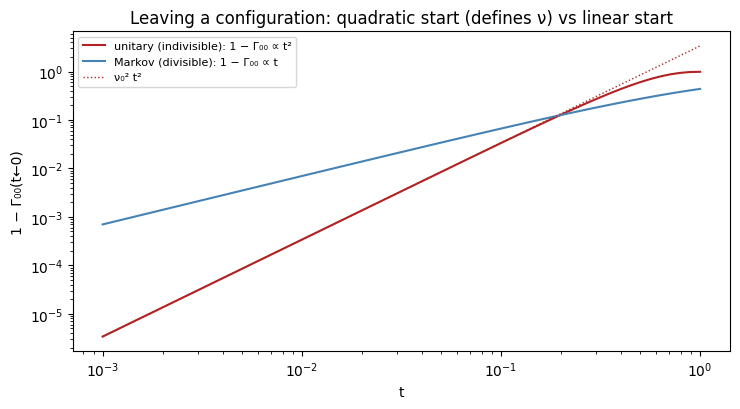

In [3]:
for N in (3, 4, 5):
    H = random_H(N)
    nu = agility(unitary_process(H))
    sd = np.sqrt(np.real(np.diag(H @ H)) - np.real(np.diag(H)) ** 2)
    print(f'N = {N}:  nu from Gamma = {nu.round(5)}')
    print(f'        std of H        = {sd.round(5)}   (max diff {np.abs(nu - sd).max():.1e})')
print(f'qubit:  nu = {agility(qubit).round(5)}   (omega / 2 = {OMEGA / 2})')
h = 1e-6
print(f"Markov: Gamma_00'(0) = {(markov(h)[0, 0] - 1) / h:.3f}  -> linear departure, no finite nu")

ts = np.logspace(-3, 0, 60)
H4 = random_H(4)
G4 = unitary_process(H4)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.loglog(ts, [1 - G4(t)[0, 0] for t in ts], color='firebrick', label='unitary (indivisible): 1 − Γ₀₀ ∝ t²')
ax.loglog(ts, [1 - markov(t)[0, 0] for t in ts], color='steelblue', label='Markov (divisible): 1 − Γ₀₀ ∝ t')
ax.loglog(ts, agility(G4)[0] ** 2 * ts ** 2, ':', color='firebrick', lw=1, label='ν₀² t²')
ax.set_xlabel('t'); ax.set_ylabel('1 − Γ₀₀(t←0)')
ax.set_title('Leaving a configuration: quadratic start (defines ν) vs linear start')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Inequality 1: Clock Precision

Started in configuration $j$, the configuration found at time $t$ is a clock reading. The information it carries
about $t$ is the Fisher information of column $j$:

$$I_j(t) = \sum_i \frac{\dot\Gamma_{ij}(t \leftarrow 0)^2}{\Gamma_{ij}(t \leftarrow 0)} \;\le\; 4\,\nu_j^2 .$$

By the Cramér–Rao bound, any unbiased estimate of $t$ from $n$ observed runs has spread
$\delta t \ge 1/\sqrt{n\,I_j}$, so

$$\delta t \cdot \nu_j \;\ge\; \frac{1}{2\sqrt n}.$$

This is an energy–time uncertainty relation, in its parameter-estimation form (Braunstein–Caves–Milburn), with Γ on
both sides and no ħ.
Equality holds as $t \to 0$. The qubit saturates it at every $t$. A Markov process has
$I_j(t) \to \infty$ as $t \to 0$, so it obeys no such bound.

This is the one step whose proof is borrowed (classical Fisher information ≤ quantum Fisher information,
Braunstein–Caves 1994). Everything after it uses Γ alone.

**Prior work.** The bound is known. Braunstein, Caves and Milburn (1996, quant-ph/9507004) state this clock bound for the
statistics of a fixed measurement, with the energy spread as the agility. Here it is only rewritten with ν read off Γ.

30 random H (N = 2..6):  max over j, t of  I_j(t) / 4 nu_j^2 = 1.000000


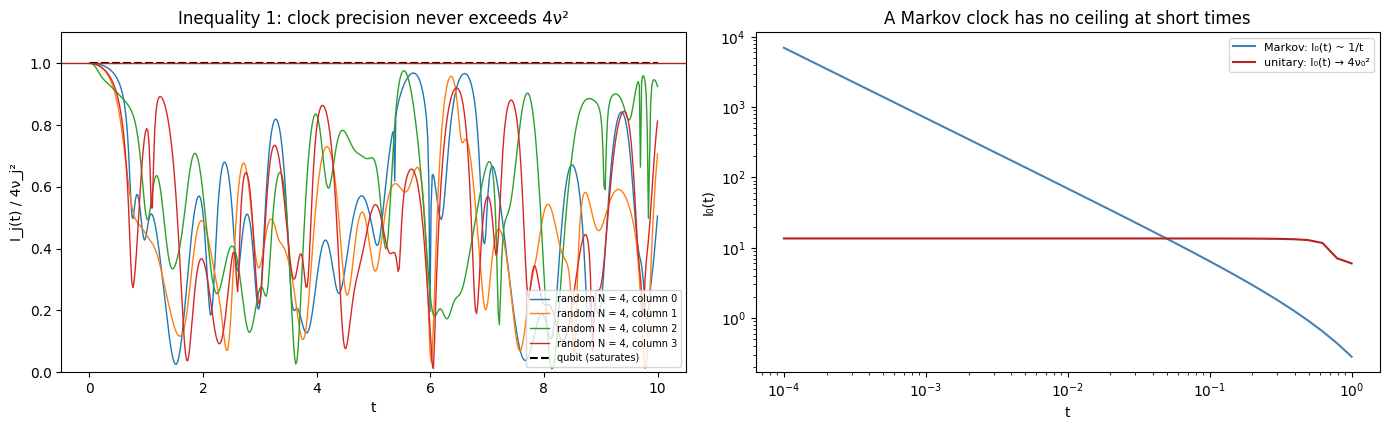

In [4]:
ts = np.linspace(0.01, 10, 500)
worst = 0.0
for _ in range(30):
    H = random_H(rng.integers(2, 7))
    G, nu = unitary_process(H), agility(unitary_process(H))
    worst = max(worst, max((fisher(G, t) / (4 * nu ** 2)).max() for t in ts))
print(f'30 random H (N = 2..6):  max over j, t of  I_j(t) / 4 nu_j^2 = {worst:.6f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
nu4 = agility(G4)
ratios = np.array([fisher(G4, t) / (4 * nu4 ** 2) for t in ts])
for j in range(4):
    axes[0].plot(ts, ratios[:, j], lw=1, label=f'random N = 4, column {j}')
axes[0].plot(ts, [fisher(qubit, t)[0] / (4 * agility(qubit)[0] ** 2) for t in ts], 'k--', lw=1.5,
             label='qubit (saturates)')
axes[0].axhline(1, color='firebrick', lw=1)
axes[0].set_ylim(0, 1.1)
axes[0].set_xlabel('t'); axes[0].set_ylabel('I_j(t) / 4ν_j²')
axes[0].set_title('Inequality 1: clock precision never exceeds 4ν²')
axes[0].legend(fontsize=7, loc='lower right')

small = np.logspace(-4, 0, 40)
axes[1].loglog(small, [fisher(markov, t)[0] for t in small], color='steelblue', label='Markov: I₀(t) ~ 1/t')
axes[1].loglog(small, [fisher(G4, t)[0] for t in small], color='firebrick', label='unitary: I₀(t) → 4ν₀²')
axes[1].set_xlabel('t'); axes[1].set_ylabel('I₀(t)')
axes[1].set_title('A Markov clock has no ceiling at short times')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

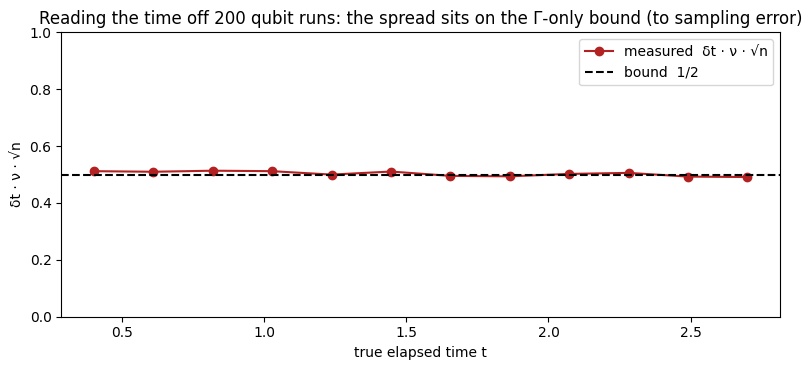

In [5]:
# Cramér–Rao in action: estimate t from n runs of the qubit, many times over
n, reps = 200, 4000
nu_q = agility(qubit)[0]
t_true = np.linspace(0.4, 2.7, 12)
spread = []
for t in t_true:
    k = rng.binomial(n, np.sin(OMEGA * t / 2) ** 2, size=reps)
    t_hat = (2 / OMEGA) * np.arcsin(np.sqrt(k / n))         # maximum-likelihood estimate
    spread.append(t_hat.std())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t_true, np.array(spread) * nu_q * np.sqrt(n), 'o-', color='firebrick', label='measured  δt · ν · √n')
ax.axhline(0.5, color='black', ls='--', label='bound  1/2')
ax.set_ylim(0, 1)
ax.set_xlabel('true elapsed time t'); ax.set_ylabel('δt · ν · √n')
ax.set_title(f'Reading the time off {n} qubit runs: the spread sits on the Γ-only bound (to sampling error)')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Inequality 2: A Speed Limit on Recovering Distinguishability

Measure how distinguishable starting configurations $j$ and $k$ are at time $t$ by the angle between columns,

$$\theta_{jk}(t) = \arccos \sum_i \sqrt{\Gamma_{ij}(t \leftarrow 0)\,\Gamma_{ik}(t \leftarrow 0)} \;\in [0, \pi/2].$$

- **Divisible** at $t'$ ($\Gamma(t \leftarrow t')$ stochastic for every $t > t'$): $\theta_{jk}$ cannot increase after $t'$
  (a stochastic map cannot decrease the Bhattacharyya coefficient).
- **Indivisible, with a fixed $H$**: $\theta_{jk}$ can increase, which is recovery, but never faster than

$$\big|\dot\theta_{jk}(t)\big| \;\le\; \nu_j + \nu_k .$$

**Derivation from inequality 1, using only Γ.** The map $p \mapsto \sqrt p$ puts every column on the unit sphere, where
$\theta_{jk}$ is the great-circle distance. Column $j$ moves on that sphere at speed $\tfrac12\sqrt{I_j} \le \nu_j$. Two points whose speeds are
at most $\nu_j$ and $\nu_k$ cannot separate faster than $\nu_j + \nu_k$.

**Prior work.** This is a one-line corollary of the Fisher-information speed limits of Nishiyama and Hasegawa
(Phys. Rev. E 114, 014120, 2026; arXiv:2504.04790), applied to two columns at once.

**Corollary for the distance used in notebooks 03 and 06.** Total variation obeys $D_{jk} \le \sin\theta_{jk}$, so

$$D_{jk}(t) \;\le\; \sin\!\Big(\min\big\{\tfrac{\pi}{2},\; \theta_{jk}(t') + (\nu_j + \nu_k)(t - t')\big\}\Big) \qquad \text{for } t \ge t'.$$

In [6]:
ts = np.linspace(0.01, 12, 1200)
worst_speed, worst_recover, worst_tv = 0.0, 0.0, -1.0
for _ in range(30):
    H = random_H(rng.integers(2, 7))
    G, nu = unitary_process(H), agility(unitary_process(H))
    P = np.array([G(t) for t in ts])
    th = np.array([angle(p) for p in P])
    rate = np.diff(th, axis=0) / np.diff(ts)[:, None, None]
    bound = nu[:, None] + nu[None, :]
    worst_speed = max(worst_speed, (np.abs(rate) / bound).max())
    worst_recover = max(worst_recover, (rate / bound).max())
    for _ in range(200):
        a, b = sorted(rng.choice(ts.size, 2, replace=False))
        cap = np.minimum(np.pi / 2, th[a] + (nu[:, None] + nu[None, :]) * (ts[b] - ts[a]))
        worst_tv = max(worst_tv, (tv(P[b]) - np.sin(cap)).max())
print(f'30 random H:  max |dθ/dt| / (ν_j + ν_k) = {worst_speed:.6f}   (bound: 1; reached by the two-state draws)')
print(f'              max recovery rate (θ rising) / (ν_j + ν_k) = {worst_recover:.6f}')
print(f'              max  D(t) − sin(cap)       = {worst_tv:.2e}   (bound: 0)')
th_m = np.array([angle(markov(t)) for t in ts])
print(f'Markov:       largest increase of any θ_jk between samples = {np.diff(th_m, axis=0).max():.1e}   (theory: ≤ 0; a positive value this small is floating-point noise)')

30 random H:  max |dθ/dt| / (ν_j + ν_k) = 1.000000   (bound: 1; reached by the two-state draws)
              max recovery rate (θ rising) / (ν_j + ν_k) = 1.000000
              max  D(t) − sin(cap)       = -9.75e-08   (bound: 0)
Markov:       largest increase of any θ_jk between samples = 7.5e-08   (theory: ≤ 0; a positive value this small is floating-point noise)


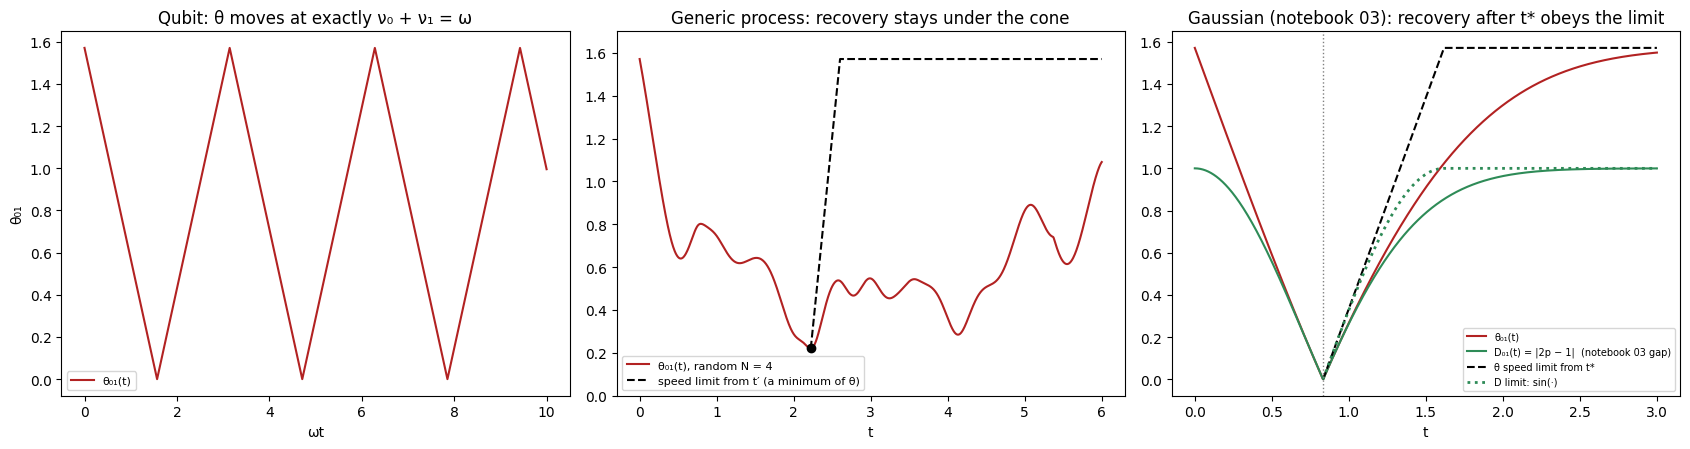

In [7]:
def G_gauss(t):
    p = np.exp(-t ** 2)
    return np.array([[p, 1 - p], [1 - p, p]])


T_STAR = np.sqrt(np.log(2))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ts = np.linspace(0, 10, 2000)
axes[0].plot(ts, [angle(qubit(t))[0, 1] for t in ts], color='firebrick', label='θ₀₁(t)')
axes[0].set_title('Qubit: θ moves at exactly ν₀ + ν₁ = ω')
axes[0].set_xlabel('ωt'); axes[0].set_ylabel('θ₀₁')
axes[0].legend(fontsize=8)

ts = np.linspace(0, 6, 1200)
th = np.array([angle(G4(t))[0, 1] for t in ts])
nu4 = agility(G4)
i0 = np.argmin(th[: len(ts) // 2])
cone = th[i0] + (nu4[0] + nu4[1]) * (ts - ts[i0])
axes[1].plot(ts, th, color='firebrick', label='θ₀₁(t), random N = 4')
axes[1].plot(ts[i0:], np.minimum(cone[i0:], np.pi / 2), '--', color='black', label="speed limit from t′ (a minimum of θ)")
axes[1].plot(ts[i0], th[i0], 'o', color='black')
axes[1].set_ylim(0, 1.7)
axes[1].set_xlabel('t'); axes[1].set_title('Generic process: recovery stays under the cone')
axes[1].legend(fontsize=8)

ts = np.linspace(0, 3, 1200)
nu_g = agility(G_gauss)
th_g = np.array([angle(G_gauss(t))[0, 1] for t in ts])
D_g = np.array([tv(G_gauss(t))[0, 1] for t in ts])
after = ts >= T_STAR
axes[2].plot(ts, th_g, color='firebrick', label='θ₀₁(t)')
axes[2].plot(ts, D_g, color='seagreen', label='D₀₁(t) = |2p − 1|  (notebook 03 gap)')
axes[2].plot(ts[after], np.minimum((nu_g[0] + nu_g[1]) * (ts[after] - T_STAR), np.pi / 2), '--', color='black',
             label='θ speed limit from t*')
axes[2].plot(ts[after], np.sin(np.minimum((nu_g[0] + nu_g[1]) * (ts[after] - T_STAR), np.pi / 2)), ':',
             color='seagreen', lw=2, label='D limit: sin(·)')
axes[2].axvline(T_STAR, color='gray', ls=':', lw=1)
axes[2].set_xlabel('t'); axes[2].set_title('Gaussian (notebook 03): recovery after t* obeys the limit')
axes[2].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

## 4. Inequality 3: Leaving a Configuration Takes Time

Apply the same sphere argument to column $j$ and its own starting point $e_j$. The angle between them is
$\arccos\sqrt{\Gamma_{jj}}$, which grows no faster than $\nu_j$:

$$\Gamma_{jj}(t \leftarrow 0) \;\ge\; \cos^2(\nu_j t) \qquad \text{for } \nu_j t \le \pi/2 .$$

This is the Mandelstam–Tamm bound, written in Γ and derived here from inequality 1.

**Corollary.** Call an *intrinsic division event* (this lab's term) a time at which Γ becomes a permutation, so that every
configuration lands on a definite configuration and the process divides there with no environment. Barandes (Paper 1, §3.7)
introduces division events through interaction with an environment instead. A permutation needs $\Gamma_{jj} = 0$ for every
configuration that moves, so it cannot occur before $\max_j \pi/(2\nu_j)$, the maximum over the configurations that move. For the qubit that is $\omega t = \pi$, the "transparent records" spacing of notebook 06.

30 random H:  max  cos²(ν_j t) − Γ_jj(t) over ν_j t <= π/2 = 0.0e+00   (bound: <= 0)


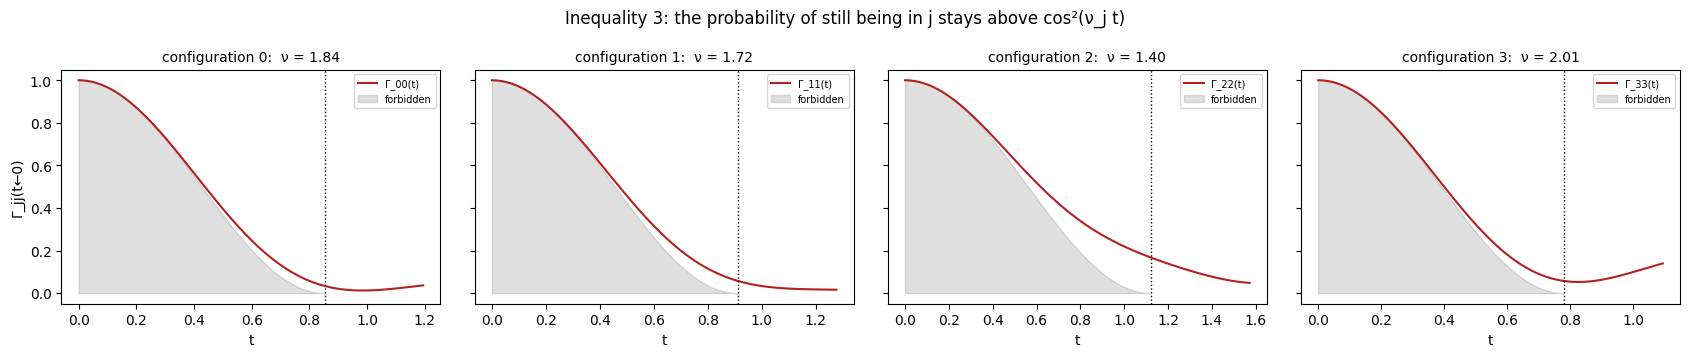

In [8]:
worst = -1.0
for _ in range(30):
    H = random_H(rng.integers(2, 7))
    G, nu = unitary_process(H), agility(unitary_process(H))
    for j in range(len(nu)):
        tt = np.linspace(0, np.pi / (2 * nu[j]), 300)
        worst = max(worst, max(np.cos(nu[j] * t) ** 2 - G(t)[j, j] for t in tt))
print(f'30 random H:  max  cos²(ν_j t) − Γ_jj(t) over ν_j t <= π/2 = {worst:.1e}   (bound: <= 0)')

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
nu4 = agility(G4)
for j, ax in enumerate(axes):
    tt = np.linspace(0, 1.4 * np.pi / (2 * nu4[j]), 400)
    ax.plot(tt, [G4(t)[j, j] for t in tt], color='firebrick', label=f'Γ_{j}{j}(t)')
    mask = nu4[j] * tt <= np.pi / 2
    ax.fill_between(tt[mask], 0, np.cos(nu4[j] * tt[mask]) ** 2, color='gray', alpha=0.25, label='forbidden')
    ax.axvline(np.pi / (2 * nu4[j]), color='black', ls=':', lw=1)
    ax.set_xlabel('t'); ax.set_title(f'configuration {j}:  ν = {nu4[j]:.2f}', fontsize=10)
    ax.legend(fontsize=7)
axes[0].set_ylabel('Γ_jj(t←0)')
plt.suptitle('Inequality 3: the probability of still being in j stays above cos²(ν_j t)')
plt.tight_layout()
plt.show()

## 5. Where the Bounds Need a Fixed Law

ν is read at $t = 0$, so the bounds need $I_j(t) \le 4\nu_j^2$ at all $t$, which a fixed $H$ guarantees. Two tests:

- **Gaussian (notebook 03).** Not of the form $|e^{-iHt}|^2$. It is a 2×2 rotation with $\cos^2\phi = e^{-t^2}$, and $\phi$ never
  moves faster than at $t=0$, so it obeys the bound.
- **An accelerating rotation**, $\Gamma = \begin{pmatrix}\cos^2\phi & \sin^2\phi\\ \sin^2\phi & \cos^2\phi\end{pmatrix}$ with $\phi = t + t^3$. Valid and indivisible, with ν = 1 at $t = 0$, but it later moves much faster.

In [9]:
def G_fast(t):
    ph = t + t ** 3
    return np.array([[np.cos(ph) ** 2, np.sin(ph) ** 2], [np.sin(ph) ** 2, np.cos(ph) ** 2]])


for name, G, t_max in [('Gaussian', G_gauss, 3.0), ('accelerating', G_fast, 1.5)]:
    nu = agility(G)
    ts = np.linspace(0.005, t_max, 1500)
    th = np.array([angle(G(t))[0, 1] for t in ts])
    rate = np.diff(th) / np.diff(ts) / (nu[0] + nu[1])
    print(f'{name:13s} nu = {nu.round(4)}   max |dθ/dt| / (ν₀ + ν₁) = {np.abs(rate).max():.3f}'
          f'   max recovery rate / (ν₀ + ν₁) = {rate.max():.3f}')

Gaussian      nu = [1. 1.]   max |dθ/dt| / (ν₀ + ν₁) = 1.000   max recovery rate / (ν₀ + ν₁) = 0.832
accelerating  nu = [1. 1.]   max |dθ/dt| / (ν₀ + ν₁) = 7.746   max recovery rate / (ν₀ + ν₁) = 7.550


## Summary

For a time-homogeneous unistochastic process, with $\nu_j = \sqrt{-\tfrac12\ddot\Gamma_{jj}(0)}$ read off Γ:

1. **Clock precision:** $\sum_i \dot\Gamma_{ij}^2/\Gamma_{ij} \le 4\nu_j^2$, hence $\delta t \cdot \nu_j \ge 1/(2\sqrt n)$. An energy–time uncertainty relation, in its parameter-estimation form.
2. **Recovery speed limit:** $|\dot\theta_{jk}| \le \nu_j + \nu_k$. Divisible processes cannot recover distinguishability at all;
   indivisible ones with a fixed $H$ can, at a bounded rate. For total variation, $D_{jk}(t) \le \sin\!\big(\min\{\tfrac\pi2,\ \theta_{jk}(t') + (\nu_j+\nu_k)(t-t')\}\big)$ for $t \ge t'$.
3. **Leaving takes time:** $\Gamma_{jj}(t) \ge \cos^2(\nu_j t)$. An intrinsic division event (Γ a permutation) cannot occur before $\max_j \pi/(2\nu_j)$ over the configurations that move.

Inequalities 2 and 3 follow from 1 by geometry on Γ alone. Inequality 1 is the single borrowed fact;
its proof currently goes through Hilbert space (Braunstein–Caves). The qubit saturates all three.
Markov semigroups (constant rates) have no finite ν; a divisible process has one only if its rates vanish at $t = 0$. The bounds require a law that does not speed up after $t = 0$; an accelerating
(time-dependent) law breaks them.

**Prior work.** None of the three bounds is new. Inequality 1, with ν as the energy spread, is the clock bound of
Braunstein, Caves and Milburn (1996), built on Braunstein–Caves (1994). Inequality 2 is a one-line corollary of
Nishiyama and Hasegawa's Fisher-information speed limits (2026). Inequality 3 is the Mandelstam–Tamm bound. Reading ν off
the $t^2$ start of $\Gamma_{jj}$ is the standard Zeno time, $\tau_Z = 1/\nu$ (Facchi & Pascazio, quant-ph/0101044), and speed limits
without ħ are known for classical dynamics (Okuyama & Ohzeki 2018; Shanahan et al. 2018). What is specific here is only the
recovery bound read as a limit on indivisibility.

**No ħ appears anywhere.** ν has units of 1/time and comes from Γ. Calling $\hbar\nu$ an energy is a units convention.